https://matplotlib.org/stable/
https://pillow.readthedocs.io/en/stable/index.html
https://numpy.org/
https://docs.python.org/

Imports des data

In [30]:
from pathlib import Path
from PIL import Image
import numpy as np


In [31]:
ROOT = Path.cwd().parent          # remonte de notebooks/ vers Détecteur AI/
dossier_train_real = ROOT / "data" / "cifake" / "train" / "REAL"
dossier_train_fake = ROOT / "data" / "cifake" / "train" / "FAKE"
print(dossier_train_real.exists())

True


In [32]:
fichiers_real = list(dossier_train_real.glob("*.jpg"))
print(len(fichiers_real))

50000


In [33]:
print(fichiers_real[0])

c:\Users\cypri\OneDrive\Bureau\Détecteur AI\data\cifake\train\REAL\0000 (10).jpg


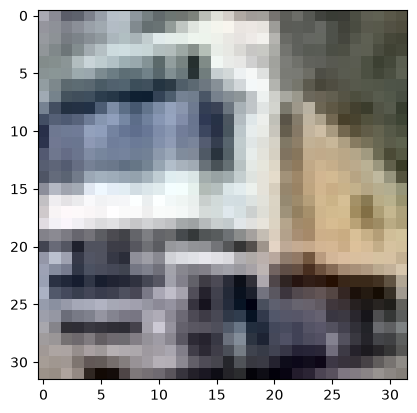

(32, 32) RGB


In [34]:
img = Image.open(fichiers_real[0])
import matplotlib.pyplot as plt

plt.imshow(img)
plt.show()
print(img.size, img.mode)

In [35]:
fichiers_real = list(dossier_train_real.glob("*.jpg"))[:10000]
fichiers_fake = list(dossier_train_fake.glob("*.jpg"))[:10000]

# Les listes vides, AVANT les boucles
X = []
y = []

# Boucle sur les images REAL -> etiquette 0
for chemin in fichiers_real:
    img = Image.open(chemin).convert("L")
    tableau = np.asarray(img)
    X.append(tableau)
    y.append(0)

# Boucle sur les images FAKE -> etiquette 1
for chemin in fichiers_fake:
    img = Image.open(chemin).convert("L")
    tableau = np.asarray(img)
    X.append(tableau)
    y.append(1)

# Transformer les listes en tableaux NumPy
X = np.array(X)
y = np.array(y)

# Verification
print("X :", X.shape, "| y :", np.bincount(y))

X : (20000, 32, 32) | y : [10000 10000]


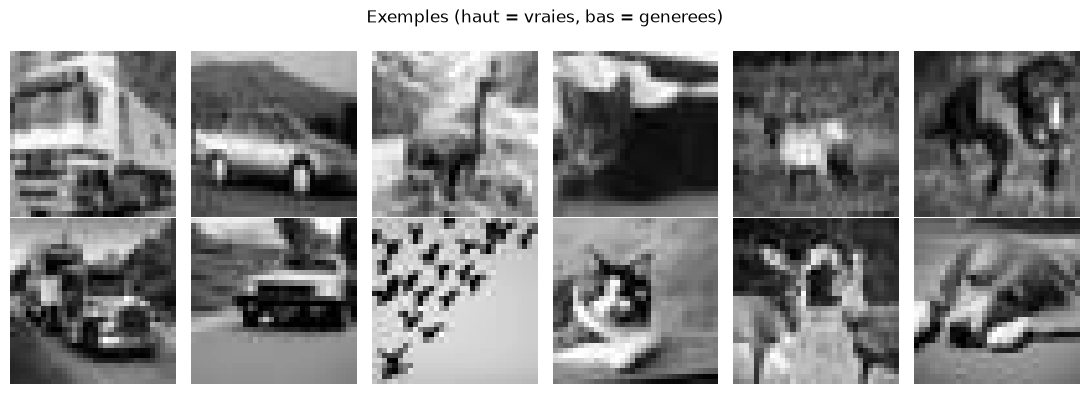

In [36]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
reals = X[y == 0][:6]
fakes = X[y == 1][:6]
for i in range(6):
    axes[0, i].imshow(reals[i], cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(fakes[i], cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_ylabel("REAL")
axes[1, 0].set_ylabel("FAKE")
fig.suptitle("Exemples (haut = vraies, bas = generees)")
fig.tight_layout()
plt.show()

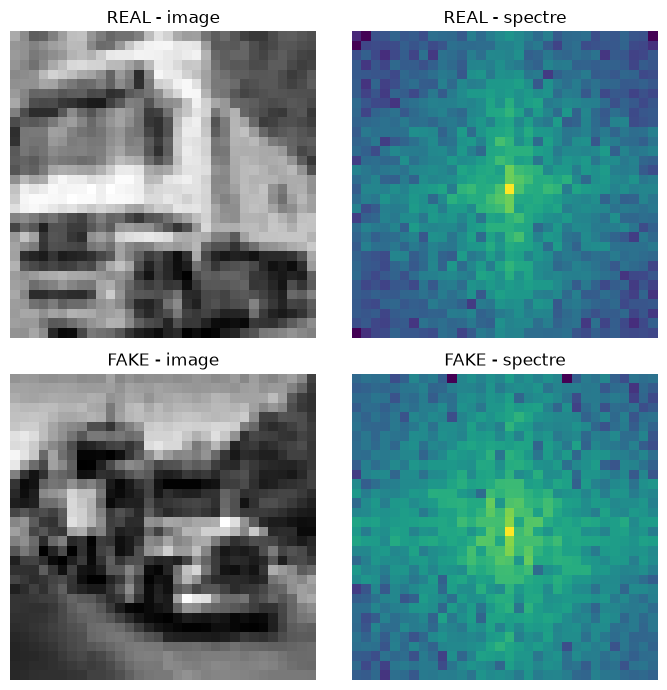

In [37]:
# On prend une image REAL et une image FAKE
img_real = X[y == 0][0]
img_fake = X[y == 1][0]

# Fonction qui calcule le spectre log d'une image
def spectre_log(image):
    f = np.fft.fft2(image)          # transformee de Fourier 2D
    f = np.fft.fftshift(f)          # frequence zero au centre
    return np.log(1+np.abs(f))   # amplitude, rendue visible

# Affichage : image + son spectre, pour REAL et pour FAKE
fig, axes = plt.subplots(2, 2, figsize=(7, 7))
axes[0, 0].imshow(img_real, cmap="gray");                  axes[0, 0].set_title("REAL - image")
axes[0, 1].imshow(spectre_log(img_real), cmap="viridis");  axes[0, 1].set_title("REAL - spectre")
axes[1, 0].imshow(img_fake, cmap="gray");                  axes[1, 0].set_title("FAKE - image")
axes[1, 1].imshow(spectre_log(img_fake), cmap="viridis");  axes[1, 1].set_title("FAKE - spectre")
for a in axes.ravel():
    a.axis("off")
fig.tight_layout()
plt.show()

comparer les deuc spectres

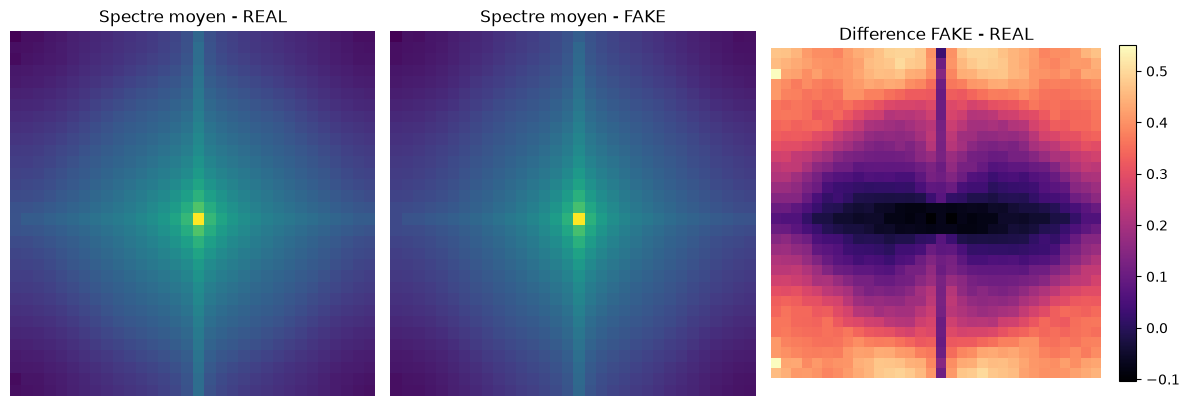

In [38]:
# Spectre moyen d'une classe
def spectre_moyen(images):
    somme = np.zeros((32, 32))        # tableau de zeros, meme taille qu'un spectre
    for image in images:
        somme += spectre_log(image)   # on additionne le spectre de chaque image
    return somme / len(images)        # on divise par le nombre d'images = moyenne

# On calcule les deux moyennes
sp_real = spectre_moyen(X[y == 0])
sp_fake = spectre_moyen(X[y == 1])

# Et leur difference
diff = sp_fake - sp_real

# Affichage des trois
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
im0 = ax[0].imshow(sp_real, cmap="viridis"); ax[0].set_title("Spectre moyen - REAL")
im1 = ax[1].imshow(sp_fake, cmap="viridis"); ax[1].set_title("Spectre moyen - FAKE")
im2 = ax[2].imshow(diff, cmap="magma");      ax[2].set_title("Difference FAKE - REAL")
for a in ax:
    a.axis("off")
fig.colorbar(im2, ax=ax[2], fraction=0.046)   # echelle de couleur pour la difference
fig.tight_layout()
plt.show()

donc là on a explorer on a vu la diff entre fake et real mantennt il faut trouver des features pour pouvoire comparer les deux 